In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# %% CELL 2: UPLOAD EXCEL FILE

import os
import tkinter as tk
from tkinter import filedialog

# Create file selection window
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

try:
    file_path = filedialog.askopenfilename(
        title="Select Your Cleaned Excel Dataset",
        filetypes=[
            ("Excel Files", "*.xlsx *.xls")
        ]
    )
finally:
    root.destroy()

# Check file selection
if not file_path:
    raise FileNotFoundError("Please select an Excel dataset!")

# Verify file
if not os.path.exists(file_path):
    raise FileNotFoundError("Selected file does not exist!")

print("EXCEL DATASET UPLOADED SUCCESSFULLY!")
print("File Name:", os.path.basename(file_path))
print("File Location:", file_path)

EXCEL DATASET UPLOADED SUCCESSFULLY!
File Name: cleaned_dataset (1).xlsx
File Location: C:/Users/Manisha Gajula/Downloads/cleaned_dataset (1).xlsx


In [7]:
# %% CELL 3: LOAD DATASET

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

Dataset loaded successfully!

First 5 Records:


,Year,From State,To State,Coal Type,Trade Type,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
0,2010,andhra pradesh,goa,anthracite coal,inter-state supply,56.15,67.88,3811.46,3811.46
1,2011,arunachal pradesh,madhya pradesh,bituminous coal,inter-state supply,27.00,90.67,2448.09,-2448.09
2,2012,assam,punjab,sub-bituminous coal,inter-state supply,63.92,142.82,9129.05,9129.05
3,2013,bihar,uttarakhand,lignite,inter-state supply,76.37,75.00,5727.75,-5727.75
4,2014,chhattisgarh,goa,anthracite coal,inter-state supply,38.75,68.43,2651.66,2651.66



Last 5 Records:


,Year,From State,To State,Coal Type,Trade Type,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
115,2023,bihar,uttarakhand,lignite,inter-state supply,11.41,86.37,985.48,-985.48
116,2024,chhattisgarh,goa,anthracite coal,inter-state supply,52.60,142.65,7503.39,7503.39
117,2025,goa,madhya pradesh,bituminous coal,inter-state supply,23.82,78.79,1876.78,-1876.78
118,2026,gujarat,punjab,sub-bituminous coal,inter-state supply,76.22,93.31,7112.09,7112.09
119,2010,haryana,uttarakhand,lignite,inter-state supply,52.56,136.23,7160.25,-7160.25


In [8]:
# %% CELL 4: DATASET INFORMATION

print("Dataset Shape:")
print(df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(120, 9)

Number of Rows: 120
Number of Columns: 9

Column Names:
['Year', 'From State', 'To State', 'Coal Type', 'Trade Type', 'Quantity (Million Tonnes)', 'Average Price (INR/Tonne)', 'Trade Value (INR Million)', 'Trade Balance Impact (INR Million)']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Year                                120 non-null    int64  
 1   From State                          120 non-null    str    
 2   To State                            120 non-null    str    
 3   Coal Type                           120 non-null    str    
 4   Trade Type                          120 non-null    str    
 5   Quantity (Million Tonnes)           120 non-null    float64
 6   Average Price (INR/Tonne)           120 non-null    float64
 7   Trade Value (INR Million)  

In [9]:
# %% CELL 5: CHECK MISSING VALUES

print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

if df.isnull().sum().sum() == 0:
    print("\nNo missing values found!")
else:
    print("\nMissing values detected!")

Missing Values in Each Column:
Year                                  0
From State                            0
To State                              0
Coal Type                             0
Trade Type                            0
Quantity (Million Tonnes)             0
Average Price (INR/Tonne)             0
Trade Value (INR Million)             0
Trade Balance Impact (INR Million)    0
dtype: int64

Total Missing Values:
0

No missing values found!


In [10]:
# %% CELL 6: DATA CLEANING

# Create a copy of original dataset
df = df.copy()

# Remove duplicate records
before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Duplicate records removed:", before - after)

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
text_columns = df.select_dtypes(
    include="object"
).columns

for column in text_columns:
    df[column] = df[column].str.strip().str.lower()

# Check missing values
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nData Cleaning Completed Successfully!")

Duplicate records removed: 0

Missing Values After Cleaning:
Year                                  0
From State                            0
To State                              0
Coal Type                             0
Trade Type                            0
Quantity (Million Tonnes)             0
Average Price (INR/Tonne)             0
Trade Value (INR Million)             0
Trade Balance Impact (INR Million)    0
dtype: int64

Data Cleaning Completed Successfully!


C:\Users\Manisha Gajula\AppData\Local\Temp\ipykernel_25868\1989391819.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(


In [11]:
# %% CELL 7: STATISTICAL ANALYSIS

print("DESCRIPTIVE STATISTICAL ANALYSIS")

display(df.describe())

print("\nMean Values:")
print(df.mean(numeric_only=True))

print("\nMedian Values:")
print(df.median(numeric_only=True))

print("\nStandard Deviation:")
print(df.std(numeric_only=True))

DESCRIPTIVE STATISTICAL ANALYSIS


,Year,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
count,120.000000,120.000000,120.000000,120.000000,120.000000
mean,2017.933333,44.804583,120.940917,5490.776083,107.946917
std,4.953113,24.564728,32.716313,3552.550213,6558.264581
min,2010.000000,5.050000,65.750000,516.510000,-14642.960000
25%,2014.000000,23.320000,91.537500,2600.767500,-4546.092500
50%,2018.000000,42.105000,124.060000,4569.480000,-214.450000
75%,2022.000000,69.495000,145.872500,7560.112500,4590.952500
max,2026.000000,84.940000,179.470000,14642.960000,14154.660000



Mean Values:
Year                                  2017.933333
Quantity (Million Tonnes)               44.804583
Average Price (INR/Tonne)              120.940917
Trade Value (INR Million)             5490.776083
Trade Balance Impact (INR Million)     107.946917
dtype: float64

Median Values:
Year                                  2018.000
Quantity (Million Tonnes)               42.105
Average Price (INR/Tonne)              124.060
Trade Value (INR Million)             4569.480
Trade Balance Impact (INR Million)    -214.450
dtype: float64

Standard Deviation:
Year                                     4.953113
Quantity (Million Tonnes)               24.564728
Average Price (INR/Tonne)               32.716313
Trade Value (INR Million)             3552.550213
Trade Balance Impact (INR Million)    6558.264581
dtype: float64


In [12]:
# %% CELL 8: YEAR-WISE ANALYSIS

year_analysis = df.groupby("Year").agg({
    "Quantity (Million Tonnes)": "sum",
    "Trade Value (INR Million)": "sum",
    "Average Price (INR/Tonne)": "mean"
}).reset_index()

print("YEAR-WISE COAL TRADING ANALYSIS")

display(year_analysis)

print("\nYear with Highest Trade Quantity:")

highest_year = year_analysis.loc[
    year_analysis["Quantity (Million Tonnes)"].idxmax()
]

print(highest_year)

YEAR-WISE COAL TRADING ANALYSIS


,Year,Quantity (Million Tonnes),Trade Value (INR Million),Average Price (INR/Tonne)
0,2010,368.00,41915.66,115.981250
1,2011,292.74,34202.51,120.811429
2,2012,374.83,45908.55,126.264286
3,2013,301.65,33463.02,123.647143
4,2014,334.35,34086.40,100.212857
5,2015,298.17,40945.65,123.520000
6,2016,302.40,35345.15,109.994286
7,2017,332.69,43375.92,126.320000
8,2018,344.40,36623.85,106.341429
9,2019,330.19,39001.55,121.078571



Year with Highest Trade Quantity:
Year                          2024.000000
Quantity (Million Tonnes)      447.960000
Trade Value (INR Million)    56276.040000
Average Price (INR/Tonne)      121.801429
Name: 14, dtype: float64


In [13]:
# %% CELL 9: COAL TYPE ANALYSIS

coal_analysis = df.groupby("Coal Type").agg({
    "Quantity (Million Tonnes)": "sum",
    "Trade Value (INR Million)": "sum",
    "Average Price (INR/Tonne)": "mean"
}).reset_index()

print("COAL TYPE ANALYSIS")

display(coal_analysis)

print("\nMost Traded Coal Type:")

most_traded_coal = coal_analysis.loc[
    coal_analysis["Quantity (Million Tonnes)"].idxmax()
]

print(most_traded_coal)

COAL TYPE ANALYSIS


,Coal Type,Quantity (Million Tonnes),Trade Value (INR Million),Average Price (INR/Tonne)
0,anthracite coal,1316.71,161948.10,122.694333
1,bituminous coal,1231.73,147314.66,116.082667
2,lignite,1444.56,175655.09,120.726667
3,sub-bituminous coal,1383.55,173975.28,124.260000



Most Traded Coal Type:
Coal Type                       lignite
Quantity (Million Tonnes)       1444.56
Trade Value (INR Million)     175655.09
Average Price (INR/Tonne)    120.726667
Name: 2, dtype: object


In [14]:
# %% CELL 10: STATE-WISE ANALYSIS

state_analysis = df.groupby("From State").agg({
    "Quantity (Million Tonnes)": "sum",
    "Trade Value (INR Million)": "sum"
}).reset_index()

state_analysis = state_analysis.sort_values(
    by="Quantity (Million Tonnes)",
    ascending=False
)

print("STATE-WISE COAL TRADING ANALYSIS")

display(state_analysis)

print("\nTop 5 States by Coal Quantity:")

display(state_analysis.head(5))

STATE-WISE COAL TRADING ANALYSIS


,From State,Quantity (Million Tonnes),Trade Value (INR Million)
15,meghalaya,265.51,38860.52
3,bihar,260.66,24320.93
1,arunachal pradesh,248.15,35099.33
10,karnataka,243.09,34739.89
4,chhattisgarh,242.53,31171.40
2,assam,237.36,34525.20
9,jharkhand,230.72,19974.17
26,uttarakhand,223.93,28021.71
7,haryana,221.72,25748.42
20,rajasthan,221.43,26255.65



Top 5 States by Coal Quantity:


,From State,Quantity (Million Tonnes),Trade Value (INR Million)
15,meghalaya,265.51,38860.52
3,bihar,260.66,24320.93
1,arunachal pradesh,248.15,35099.33
10,karnataka,243.09,34739.89
4,chhattisgarh,242.53,31171.40


In [15]:
# %% CELL 11: TRADE TYPE ANALYSIS

trade_analysis = df.groupby("Trade Type").agg({
    "Quantity (Million Tonnes)": "sum",
    "Trade Value (INR Million)": "sum",
    "Trade Balance Impact (INR Million)": "sum"
}).reset_index()

print("TRADE TYPE ANALYSIS")

display(trade_analysis)

TRADE TYPE ANALYSIS


,Trade Type,Quantity (Million Tonnes),Trade Value (INR Million),Trade Balance Impact (INR Million)
0,inter-state supply,5376.55,658893.13,12953.63


CORRELATION MATRIX


,Year,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
Year,1.000000,-0.005865,0.096428,0.073119,0.109349
Quantity (Million Tonnes),-0.005865,1.000000,0.090428,0.885293,0.000715
Average Price (INR/Tonne),0.096428,0.090428,1.000000,0.489006,0.036081
Trade Value (INR Million),0.073119,0.885293,0.489006,1.000000,0.011270
Trade Balance Impact (INR Million),0.109349,0.000715,0.036081,0.011270,1.000000


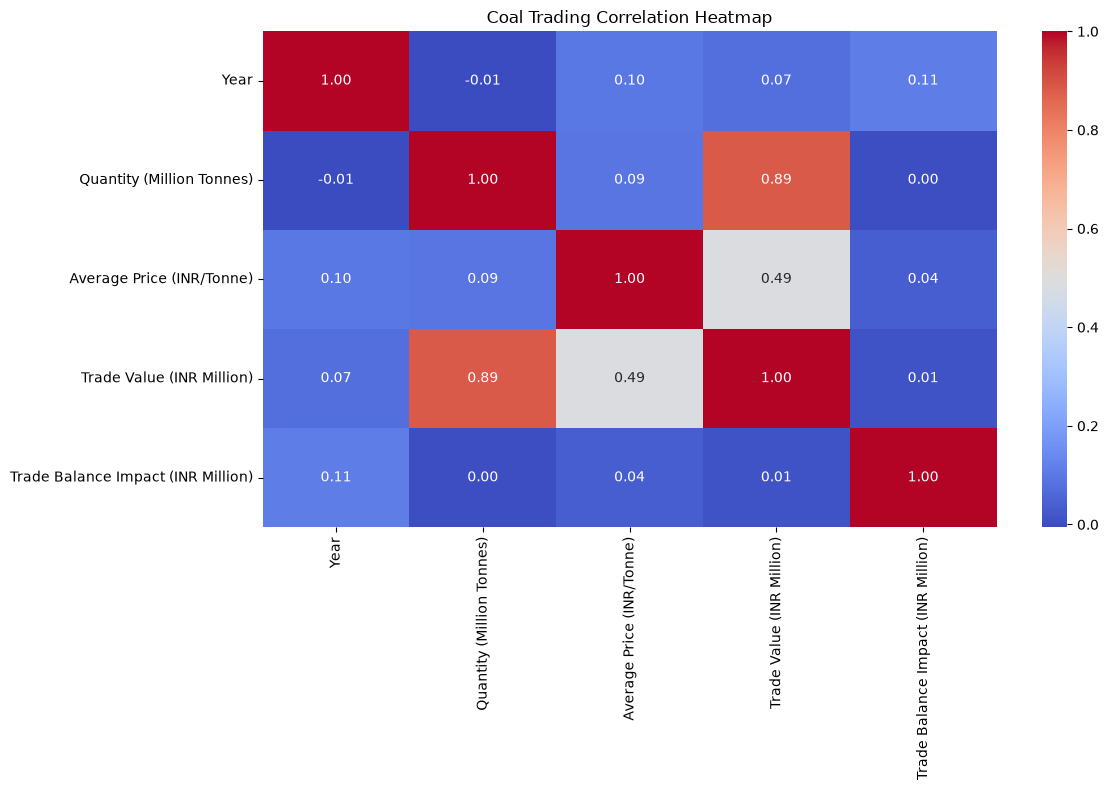

In [16]:
# %% CELL 12: CORRELATION ANALYSIS

numeric_data = df.select_dtypes(
    include=np.number
)

correlation = numeric_data.corr()

print("CORRELATION MATRIX")

display(correlation)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Coal Trading Correlation Heatmap")

plt.tight_layout()
plt.show()

In [20]:
# %% CELL 18: FINAL DATA ANALYSIS AND EXPORT

import pandas as pd
import os

# Check whether dataset exists
if 'df' not in globals():
    raise NameError("Dataset 'df' is not loaded. Load your dataset first.")

# Check whether dataset is empty
if df.empty:
    raise ValueError("Your dataset is empty!")

print("Starting final data analysis...")

# 1. Basic Dataset Analysis
basic_analysis = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum()
    ]
})

# 2. Numerical Column Analysis
numeric_columns = df.select_dtypes(include="number").columns

if len(numeric_columns) > 0:
    numeric_analysis = df[numeric_columns].describe().T.reset_index()
    numeric_analysis.rename(columns={"index": "Column"}, inplace=True)
else:
    numeric_analysis = pd.DataFrame({"Message": ["No numerical columns found"]})

# 3. State Analysis
# Automatically identify a state-related column
state_columns = [
    col for col in df.columns
    if "state" in col.lower()
]

if state_columns:
    state_analysis = (
        df[state_columns[0]]
        .value_counts(dropna=False)
        .reset_index()
    )
    state_analysis.columns = ["State", "Count"]
else:
    state_analysis = pd.DataFrame({
        "Message": ["No state column found in dataset"]
    })

# 4. Trade Analysis
trade_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in ["trade", "product", "category"])
]

if trade_columns:
    trade_analysis = (
        df[trade_columns[0]]
        .value_counts(dropna=False)
        .reset_index()
    )
    trade_analysis.columns = ["Trade Category", "Count"]
else:
    trade_analysis = pd.DataFrame({
        "Message": ["No trade/product/category column found"]
    })

# 5. Balance Analysis
# Automatically identify balance-related columns
balance_columns = [
    col for col in df.columns
    if "balance" in col.lower()
]

if balance_columns:
    balance_analysis = df[balance_columns].describe().T.reset_index()
    balance_analysis.rename(columns={"index": "Balance Column"}, inplace=True)
else:
    balance_analysis = pd.DataFrame({
        "Message": ["No balance-related column found in dataset"]
    })

# 6. Export all results to Excel
output_file = "Final_Data_Analysis_Report.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    basic_analysis.to_excel(
        writer, sheet_name="Basic Analysis", index=False
    )

    numeric_analysis.to_excel(
        writer, sheet_name="Numeric Analysis", index=False
    )

    state_analysis.to_excel(
        writer, sheet_name="State Analysis", index=False
    )

    trade_analysis.to_excel(
        writer, sheet_name="Trade Analysis", index=False
    )

    balance_analysis.to_excel(
        writer, sheet_name="Balance Analysis", index=False
    )

print("\n======================================")
print("DATA ANALYSIS COMPLETED SUCCESSFULLY!")
print("======================================")

print("Report saved as:", os.path.abspath(output_file))
print("\nGenerated Sheets:")
print("1. Basic Analysis")
print("2. Numeric Analysis")
print("3. State Analysis")
print("4. Trade Analysis")
print("5. Balance Analysis")

Starting final data analysis...

DATA ANALYSIS COMPLETED SUCCESSFULLY!
Report saved as: c:\Users\Manisha Gajula\OneDrive\Desktop\data analysis\Final_Data_Analysis_Report.xlsx

Generated Sheets:
1. Basic Analysis
2. Numeric Analysis
3. State Analysis
4. Trade Analysis
5. Balance Analysis


C:\Users\Manisha Gajula\AppData\Local\Temp\ipykernel_25868\31140557.py:37: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  numeric_analysis.rename(columns={"index": "Column"}, inplace=True)
C:\Users\Manisha Gajula\AppData\Local\Temp\ipykernel_25868\31140557.py:87: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  balance_analysis.rename(columns={"index": "Balance Column"}, inplace=True)
